# **ABSTRACT**

The challenges associated with selecting suitable farmland and determining the appropriate crops to cultivate based on soil characteristics and prevailing weather conditions have motivated the development of a Crop Plantation Recommendation System. The proposed system aims to support farmers in making informed crop selection decisions by analyzing essential agricultural factors, including soil nutrient composition, nutrient proportions, and climatic conditions.

The system is designed to integrate with a multipurpose sensor that collects real-time data directly from farmland, providing relevant information about soil conditions and environmental parameters. By processing the collected data, the system will recommend the most suitable crop types for specific farmland conditions. This approach seeks to minimize inappropriate crop selection, promote efficient land utilization, and improve agricultural productivity.

Ultimately, the proposed system aims to provide farmers with a reliable, data-driven decision-support tool that can contribute to increased crop yields, sustainable farming practices, and improved food security within the agricultural sector.

# **INTRODUCTION**

# IMPORTING THE NECCESSARY LIBRARIES

In [3]:
#Libraries for exploratory data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#Scikit learn for preprocessing and model building
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge, Lasso
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC
from sklearn.preprocessing import OneHotEncoder , StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, classification_report, mean_absolute_error,mean_squared_error,accuracy_score

#Neural Network
from tensorflow import keras
from tensorflow.keras import Sequential

#Pipeline and transformers
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.ensemble import VotingClassifier
from sklearn.compose import ColumnTransformer

# Exploratory Data Analysis

In [4]:
#reading the dataset into sheet format
df = pd.read_csv("Crop_recommendation.csv")

In [5]:
df.shape

(2200, 8)

In [6]:
df.isnull().sum() #checking for missing values in the columns

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.info() #Brief info of the dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [9]:
df.describe() #statistical summary of the dataframe

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


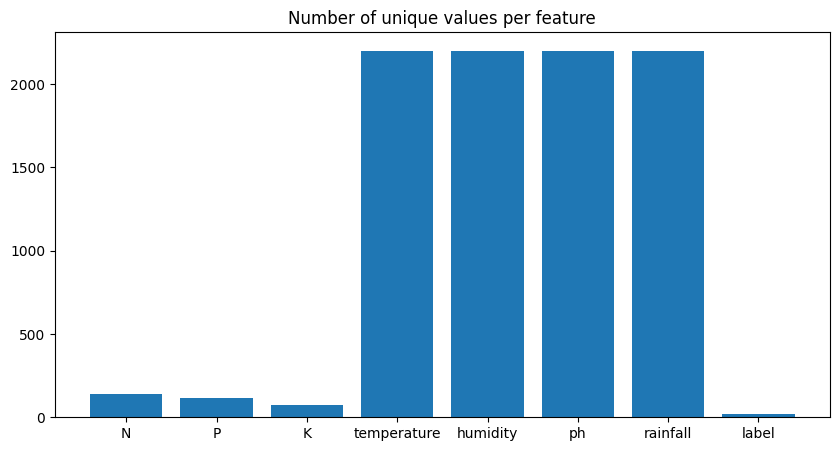

In [10]:
plt.figure(figsize=(10,5))
plt.title("Number of unique values per feature")
plt.bar(df.nunique().index,df.nunique().values); #checking for the number of unique values in the columns of each dataframe

In [11]:
df["label"].unique() #checking for unique values in the 'Label' column

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

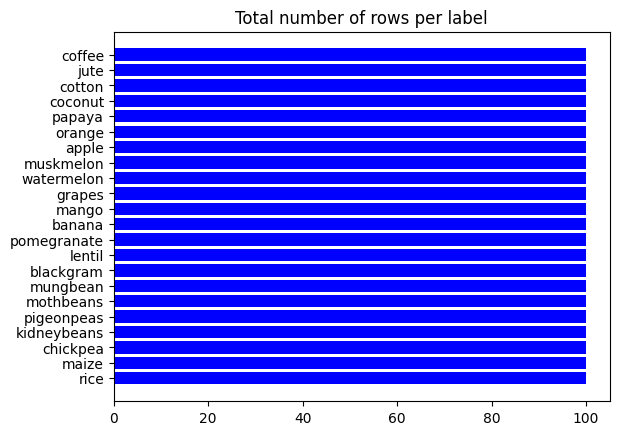

In [12]:
plt.title("Total number of rows per label")
plt.barh(df["label"].value_counts().index,df["label"].value_counts().values,color="b");#The number of unique values in the 'Label' column
#Equal sampling

In [13]:
from sklearn.preprocessing import LabelEncoder
#Encoding using label encoder to label the elements in the target column
encode = LabelEncoder()
df["label"] = encode.fit_transform(df["label"])

In [14]:
df.label.unique()

array([20, 11,  3,  9, 18, 13, 14,  2, 10, 19,  1, 12,  7, 21, 15,  0, 16,
       17,  4,  6,  8,  5])

In [15]:
num_columns = df.select_dtypes(exclude="object") #getting only the numerical portion of the data

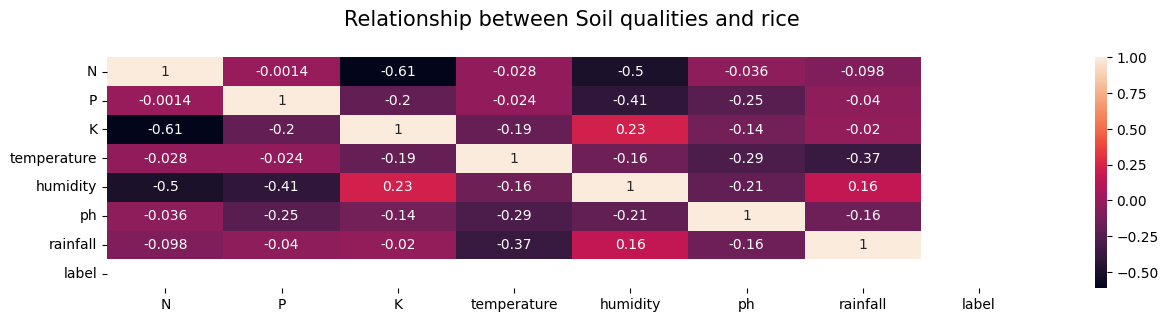

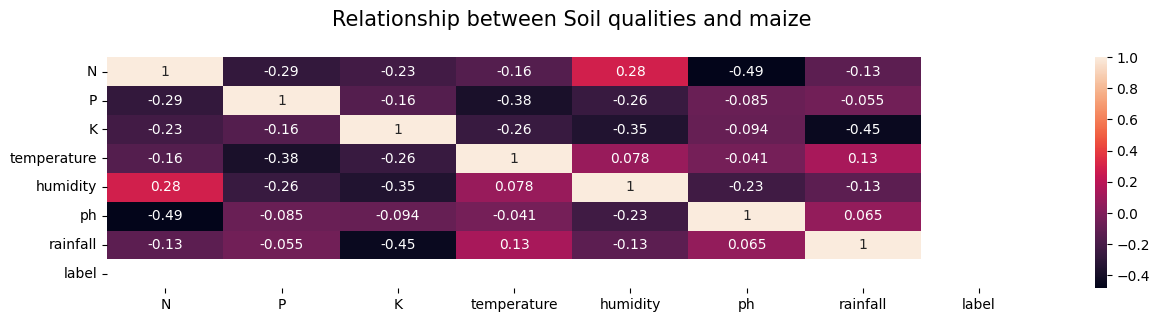

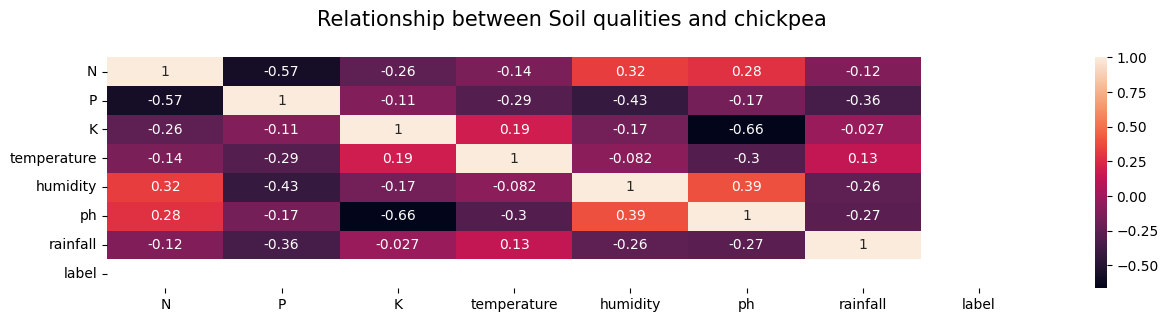

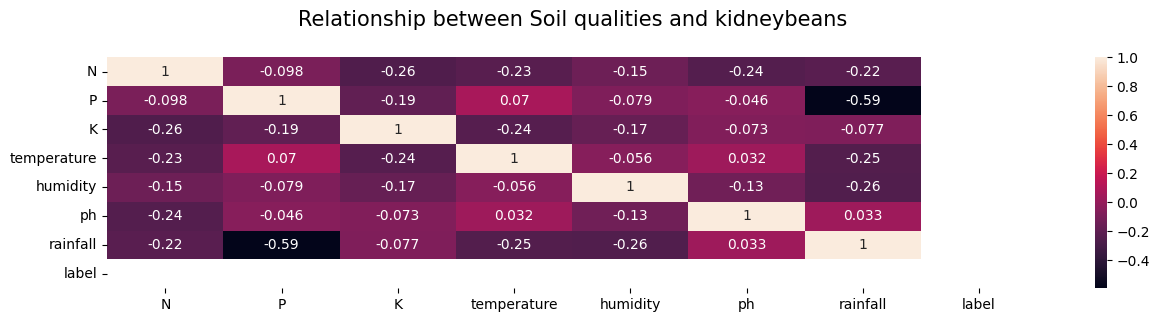

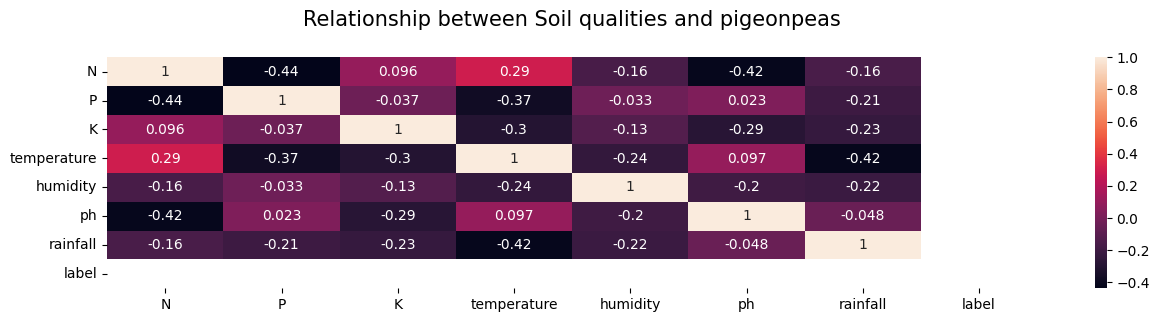

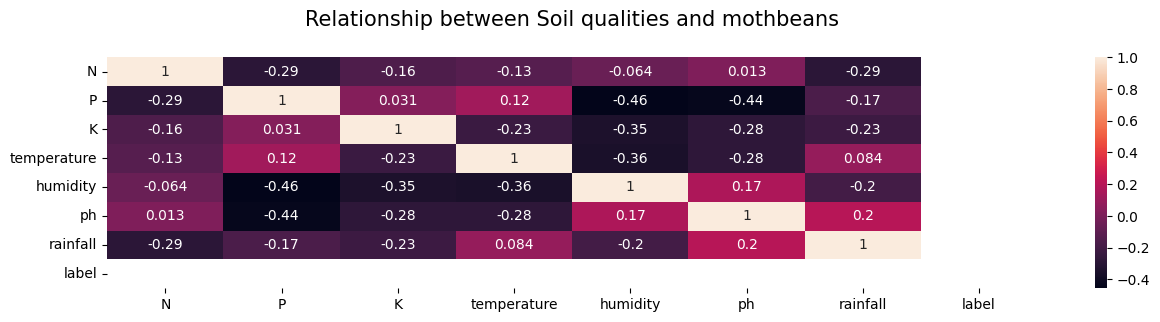

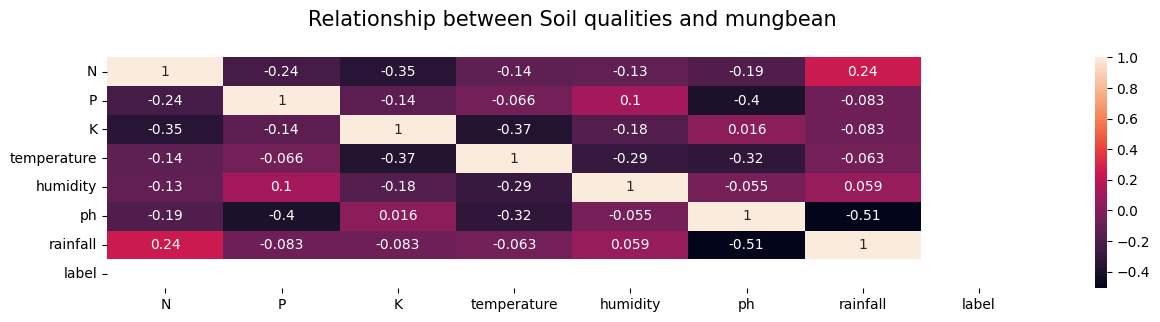

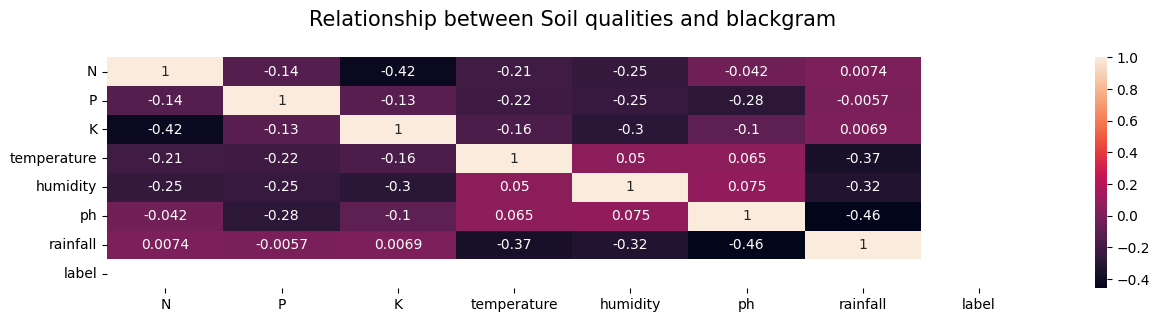

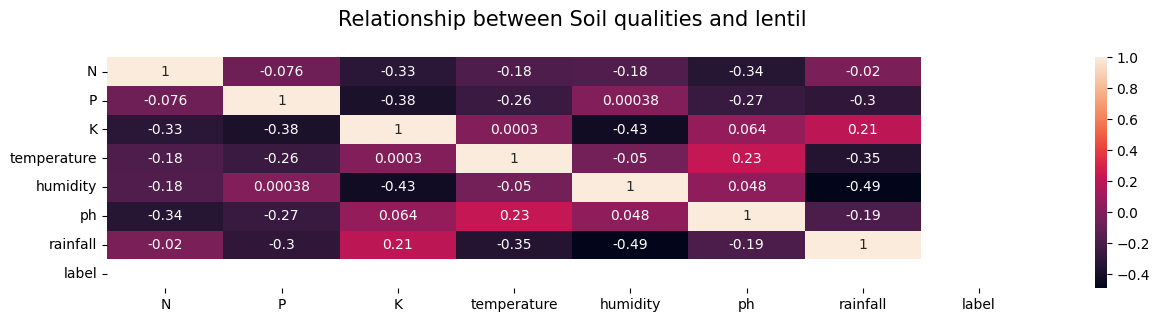

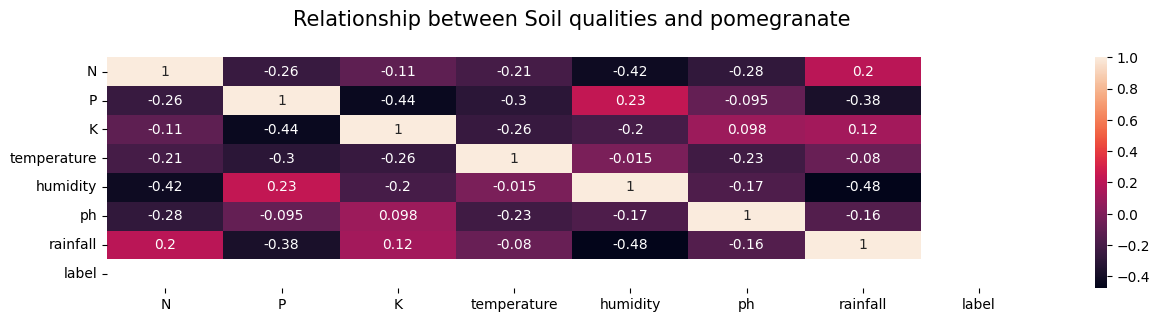

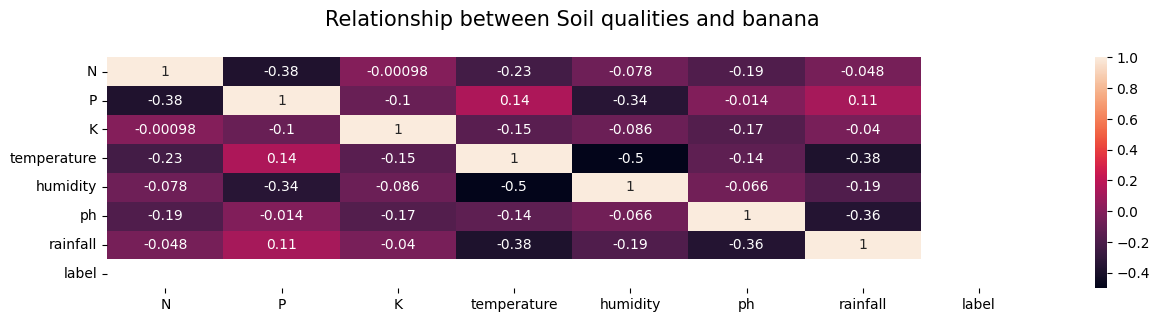

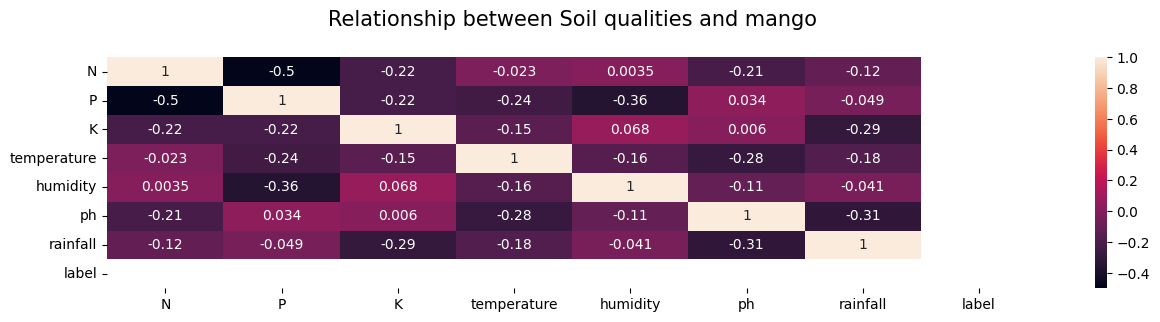

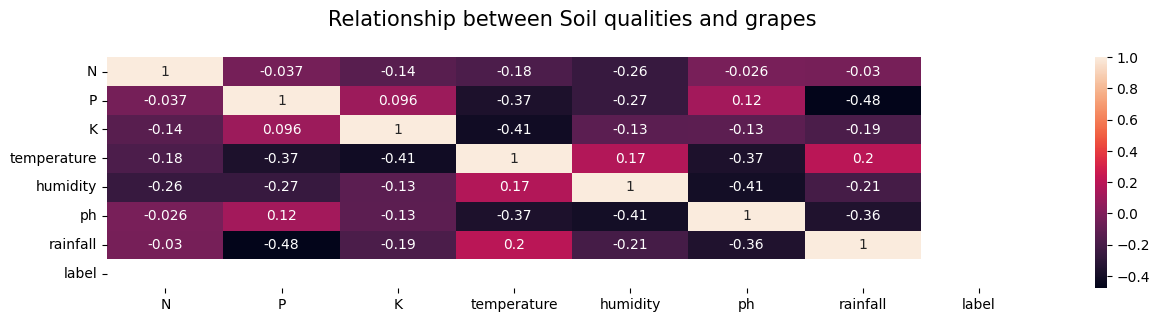

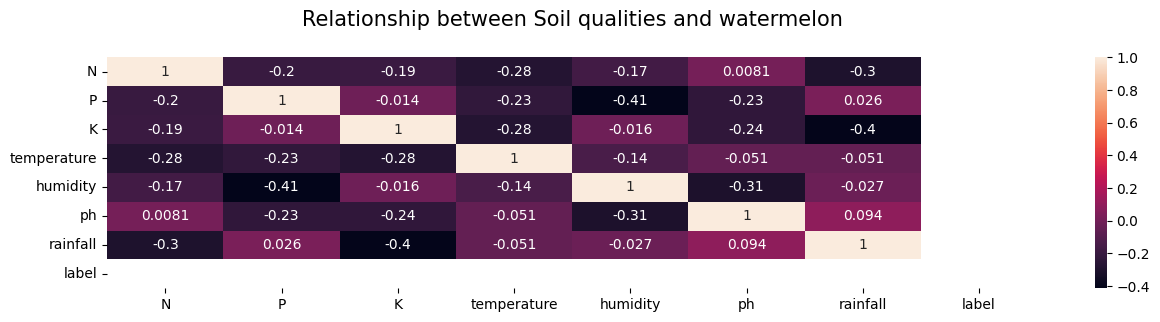

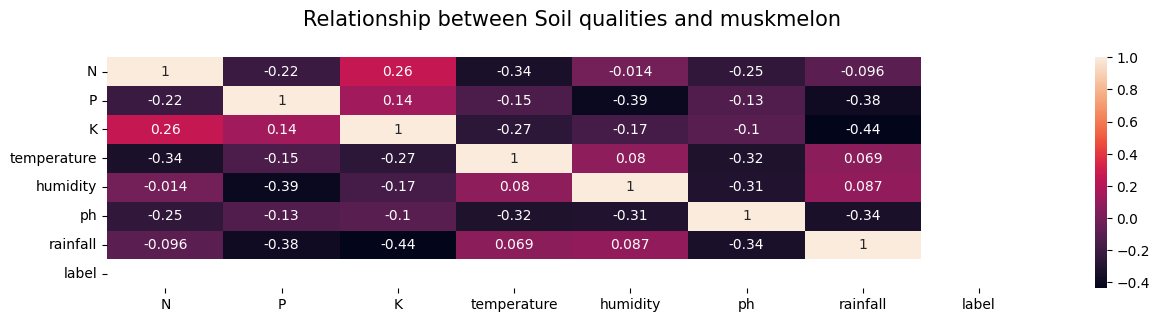

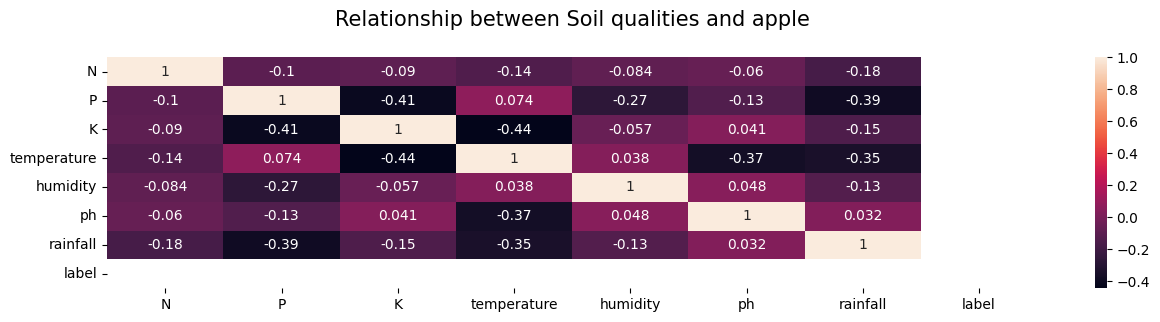

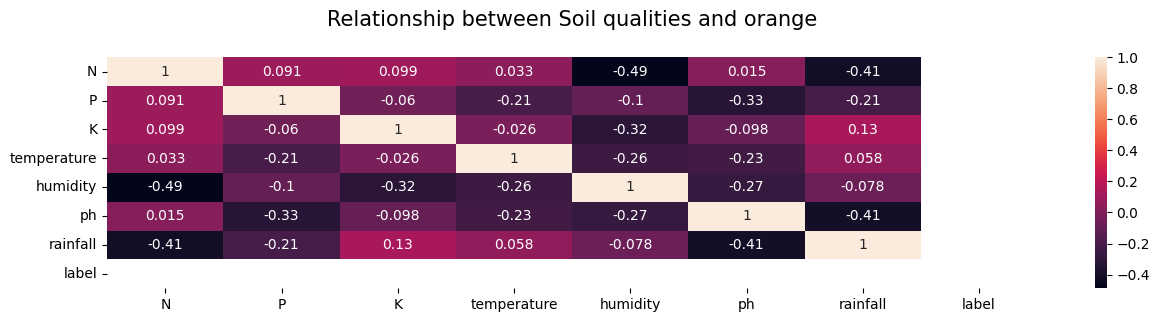

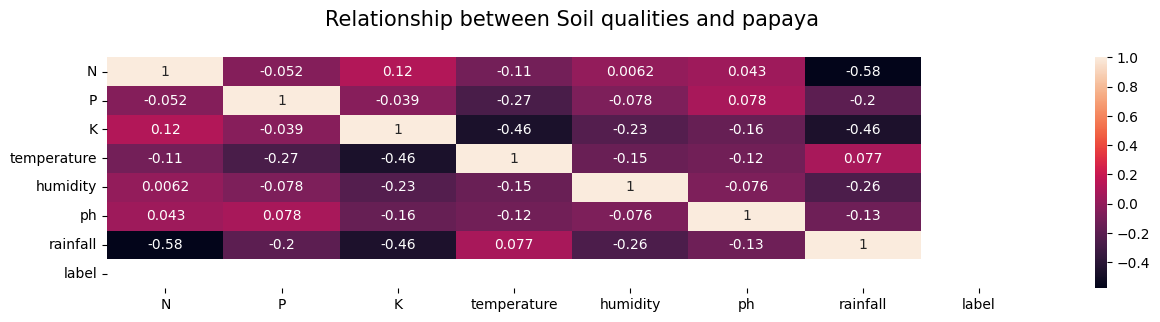

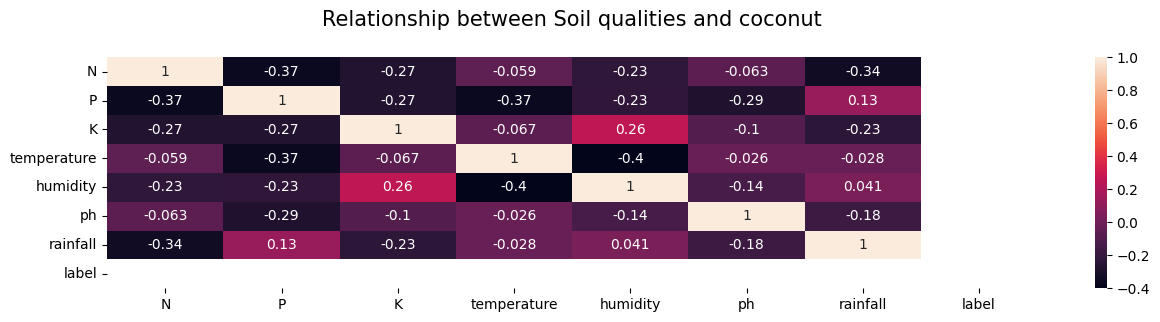

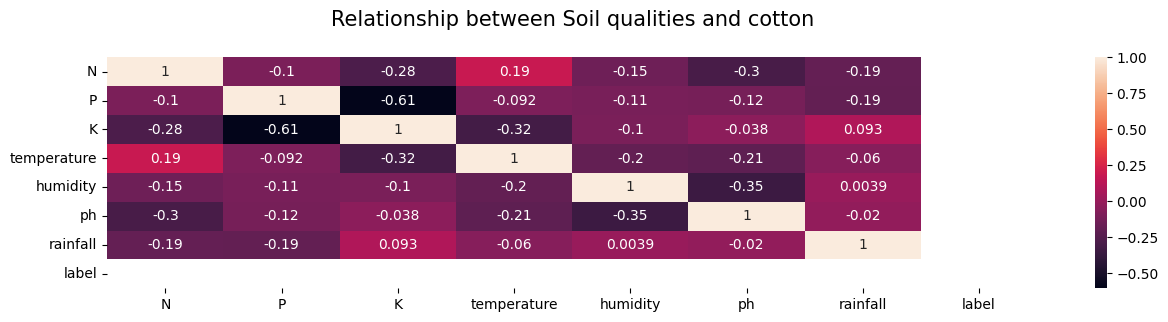

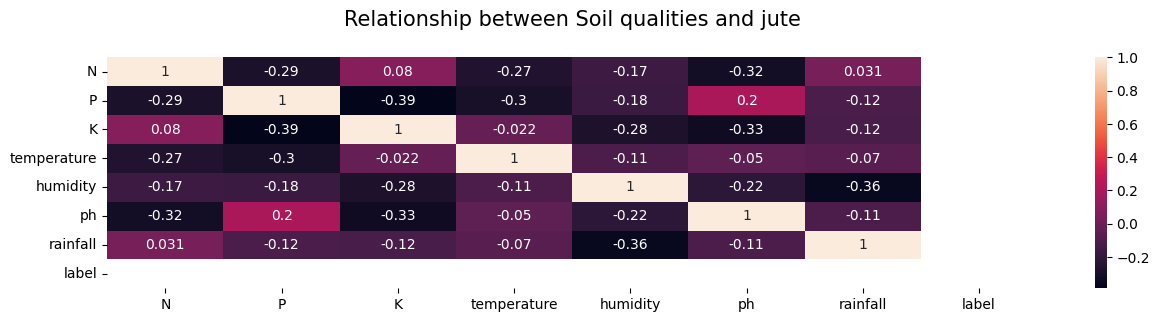

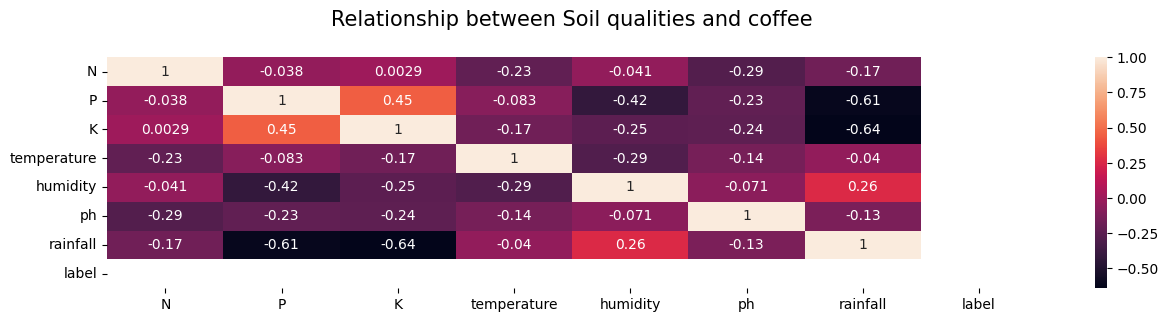

In [16]:
def HeatMap(frame):

  #Checks the relationship between soil properties and weather factors or conditions for the various crop type
  for i in df.label.unique():
    print()
    frame = df[df.label==i]
    corr = frame.select_dtypes(exclude="object").corr() #Getting the correlation of the numerical columns
    plt.figure(figsize=(15,3)) #15X3 of plot size
    #plt.subplot(1,2,1)
    sns.heatmap(corr.corr(),annot=True)
    plt.title(f"Relationship between Soil qualities and {encode.inverse_transform([i])[0]}\n",fontsize=15)
    plt.savefig("climate-soil-nutrients-crop-relationship.jpg")
    plt.show()
HeatMap(df)

# Outliers Identification and Removal

<Figure size 1500x1000 with 0 Axes>

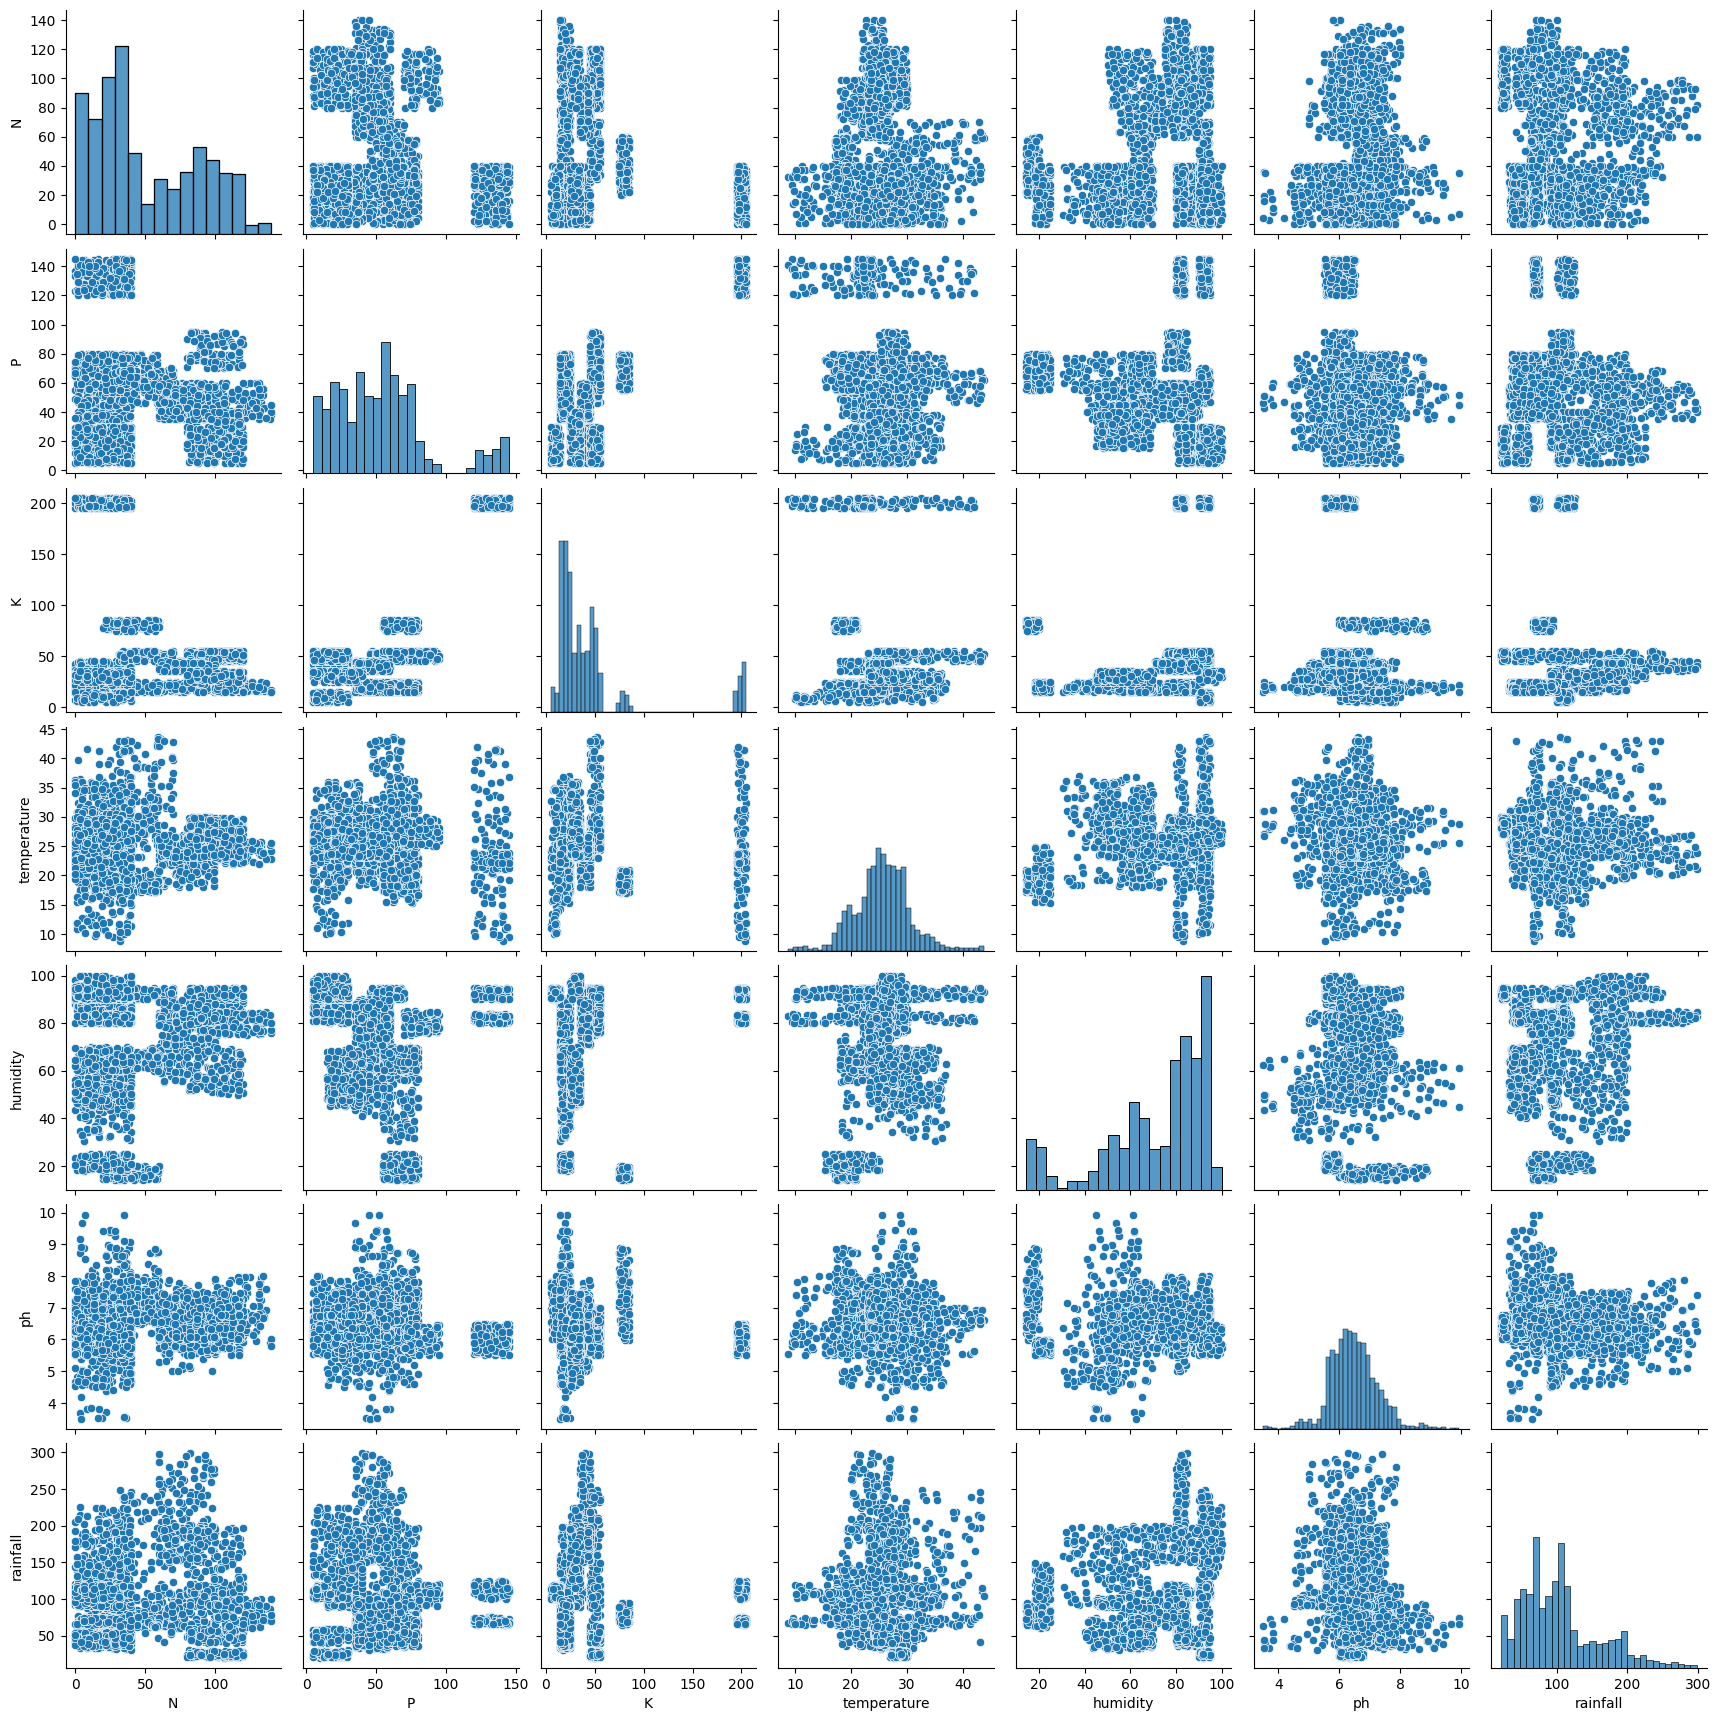

In [17]:
plt.figure(figsize=(15,10))
sns.pairplot(num_columns.drop("label",axis=1)); #A pair plot to check for the relationship between columns and to find                    # And to help find outliers in our dataset


In [18]:
#The pairplot scatter plots indicates some outliers, which are out of bounds,especially in the Potassium(K)
#Also as shown in the histogram of the K plot. Further barplot will be used for clear identification

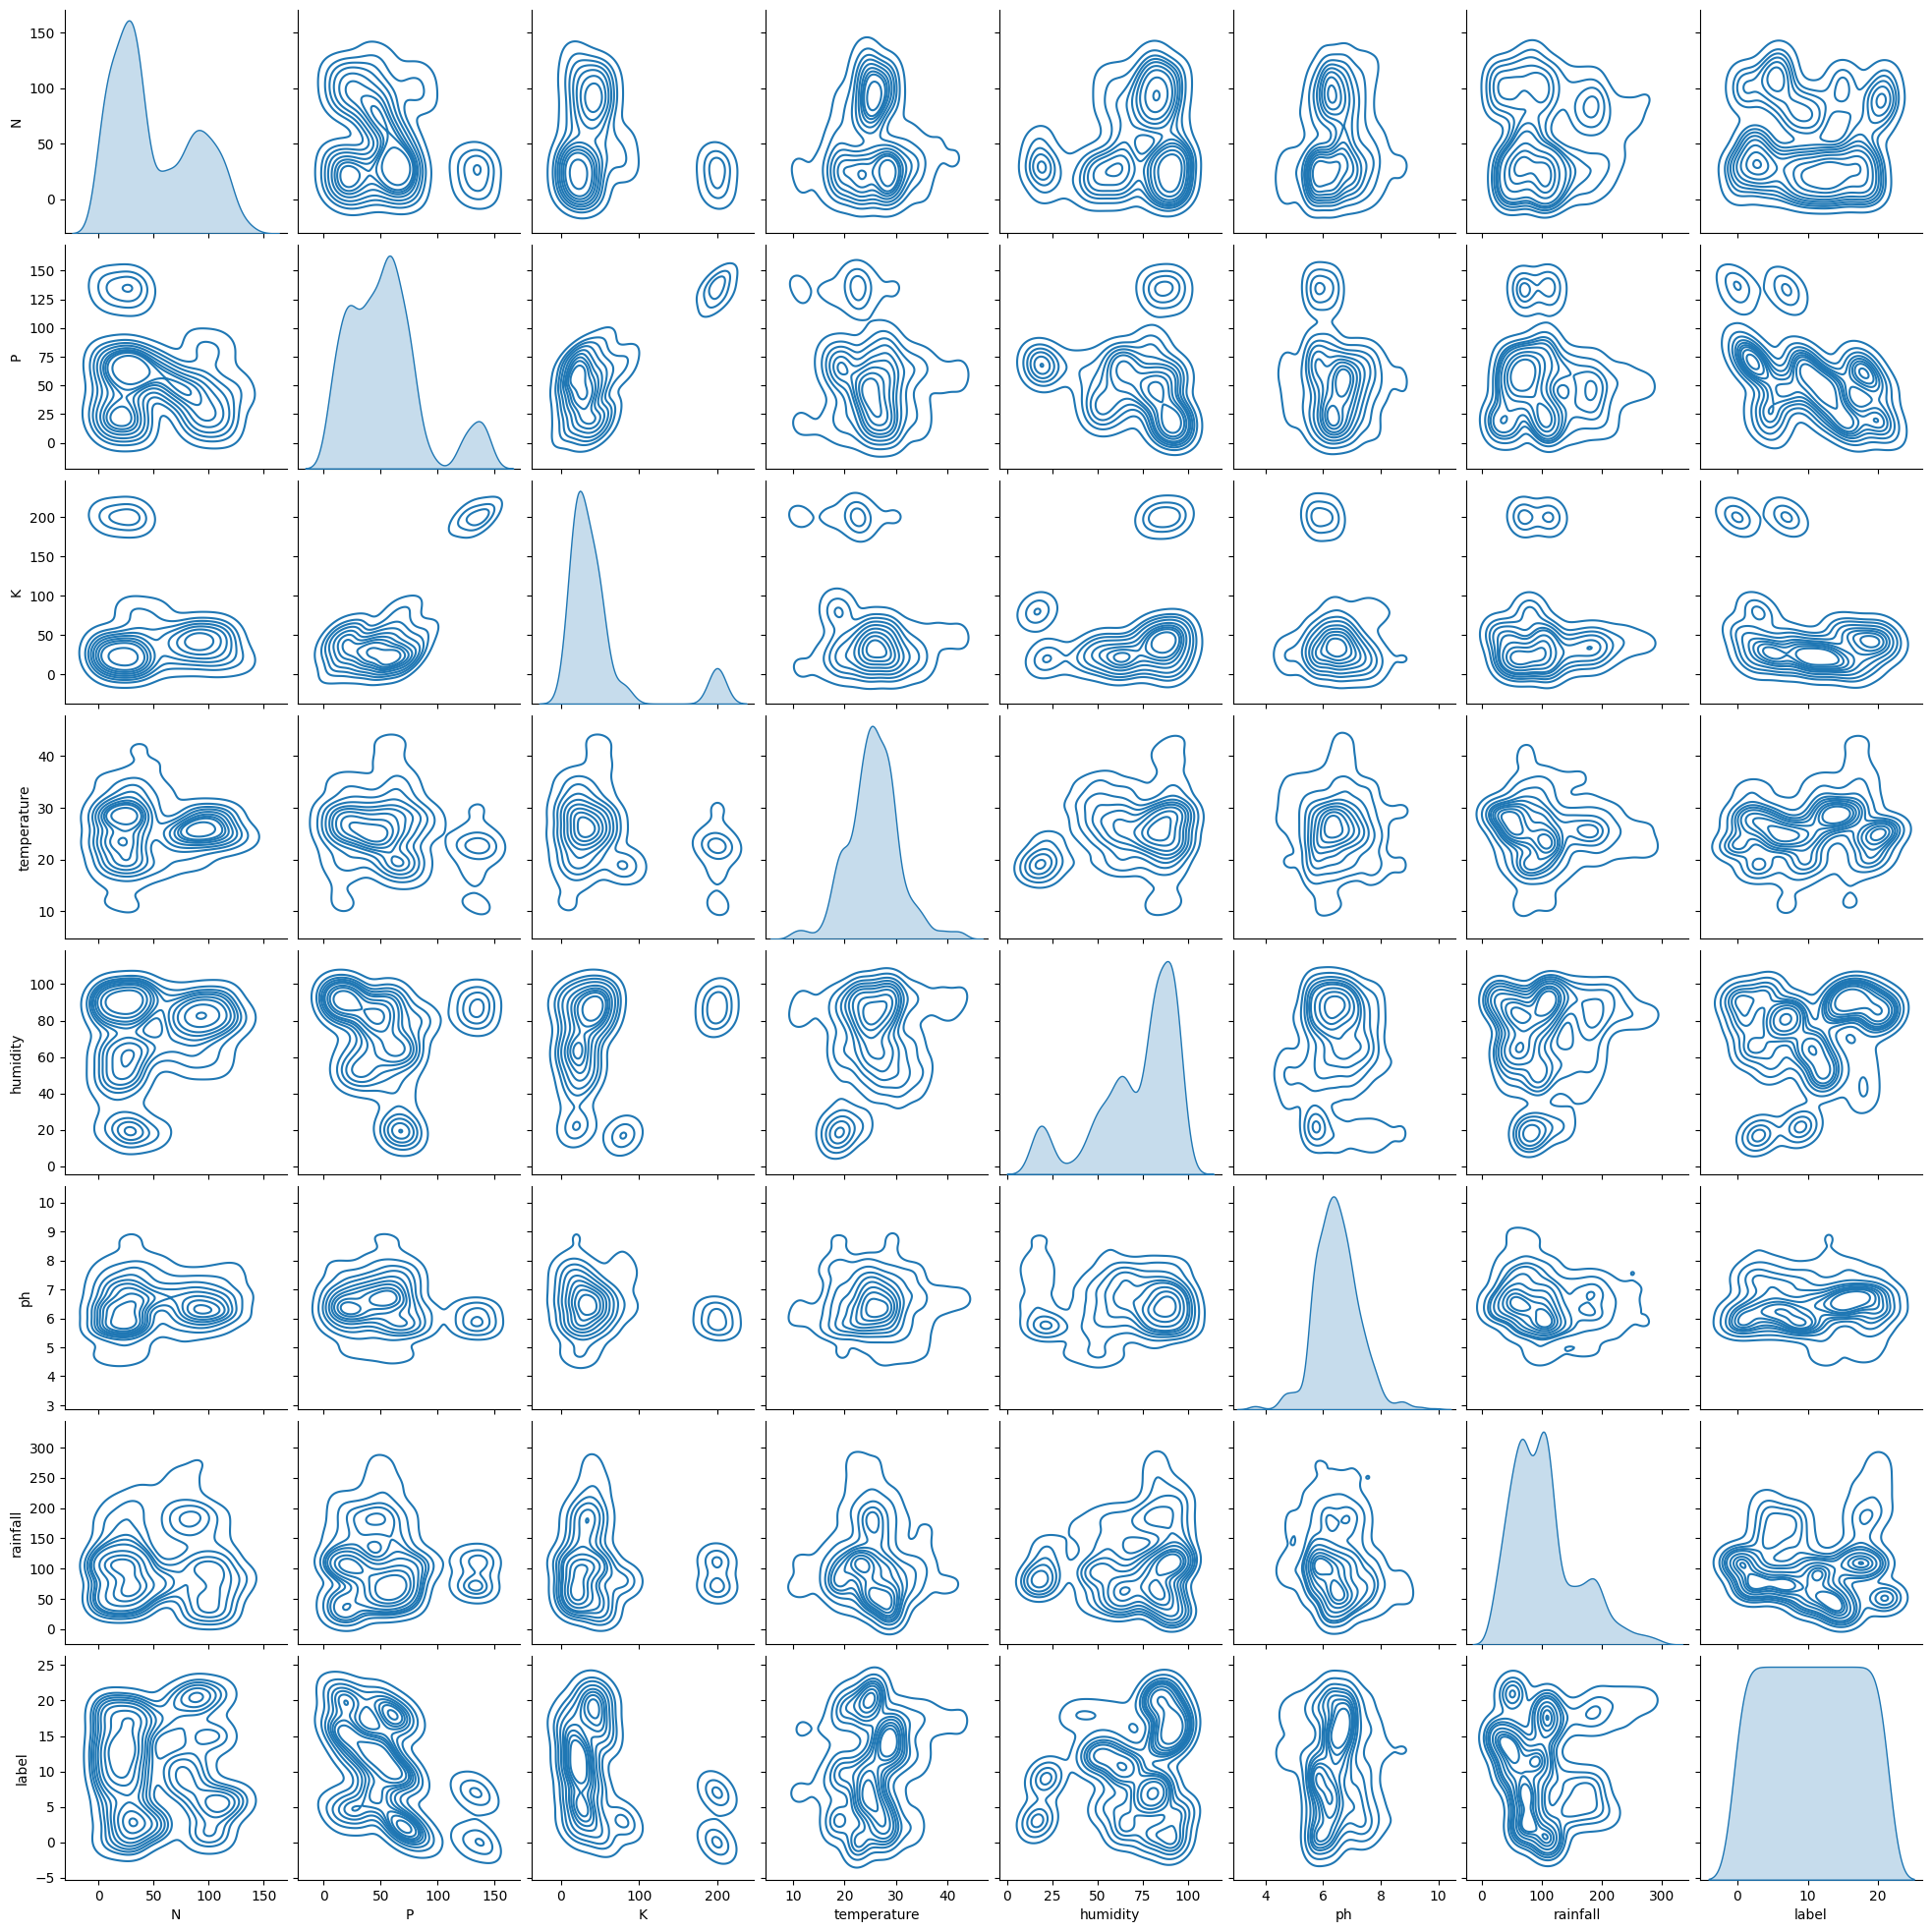

In [19]:
sns.pairplot(df,kind='kde') # Shows the relationship and the distribution
plt.savefig("Farm.jpg")
plt.show()
#which basically shows the probability density of the columns in the dataframe

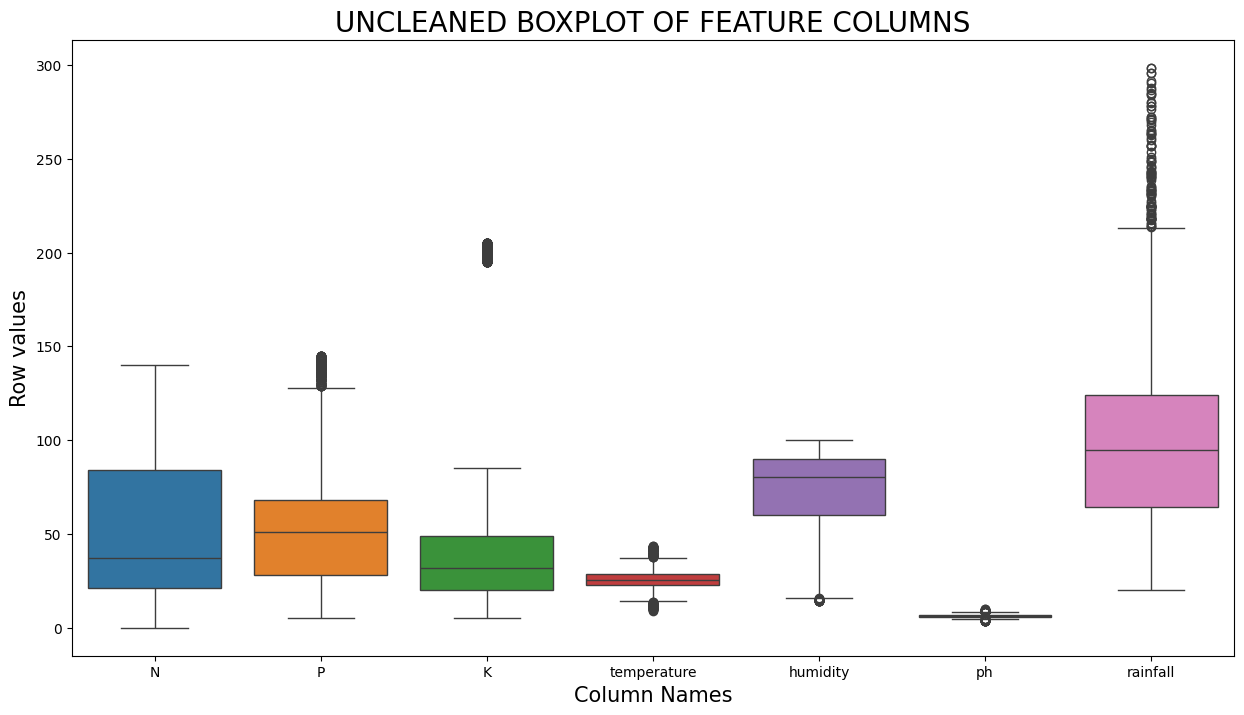

In [20]:
#Boxplot for identifying outliers
plt.figure(figsize=(15,8))
sns.boxplot(num_columns.drop("label",axis=1))
plt.title("UNCLEANED BOXPLOT OF FEATURE COLUMNS",fontsize=20)
plt.xlabel("Column Names",fontsize=15)
plt.ylabel("Row values",fontsize=15)
plt.show()

In [21]:
#Potassium(K) showed clear outliers presences
#Also rain indicates presence of outliers during peak times out heavy downpoors which is not usual
#Which are considered as outliers

### Using Interquartile Range(IQR) to remove outliers from P, K, temperature, humidity ,ph, rainfall

### Clean Phosphorus(P)

In [22]:
min(df["P"].unique()),max(df["P"].unique()) #Checking for minimum and maximum values in the Phosphorus(P) column

(np.int64(5), np.int64(145))

In [23]:
len(df["P"])

2200

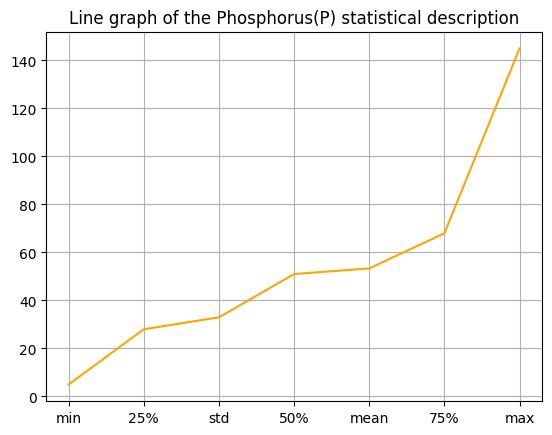

In [24]:
plt.grid(True)
plt.title("Line graph of the Phosphorus(P) statistical description")
plt.plot(df["P"].describe().drop("count",axis=0).sort_values(),color='orange',); #Statistical summary of the Phosphorus(P) column
#This shows potential outliers due to uneven distribution, it shows an exponetial distribution

In [25]:
Q1p,Q3p = df.P.quantile([0.25,0.90]) #Getting the 25% and 90% percentile of the P column

In [26]:
IQRp = (Q3p - Q1p) # Interquartile of the P column

In [27]:
#The lower and Upper limits of the P column
lower_limitp = (Q1p - 1.5*IQRp)
upper_limitp = (Q3p + 1.5*IQRp)

In [28]:
lower_limitp,upper_limitp

(-63.650000000000205, 180.75000000000034)

In [29]:
p_outliers = df[(df.P < lower_limitp) | (df.P > upper_limitp)] #Outliers less than lower limits and greater than the Upper lim
p_outliers.shape

(0, 8)

In [30]:
mask_p = ((df.P > lower_limitp) & (df.P < upper_limitp)) #Getting the good data and dropping the outliers

### Clean Potassium(K)

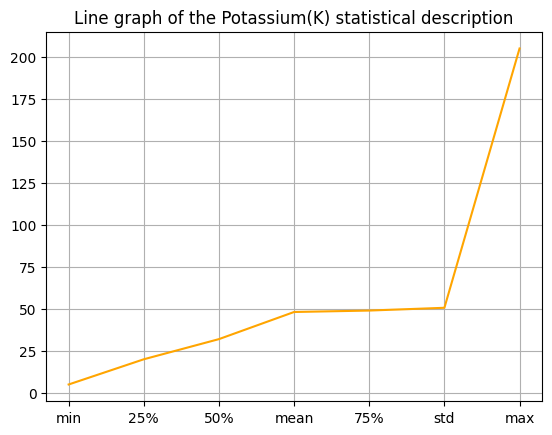

In [31]:
plt.grid(True)
plt.title("Line graph of the Potassium(K) statistical description")
plt.plot(df["K"].describe().drop("count",axis=0).sort_values(),color='orange',); #Statistical summary of the Potassium(K) column
#This shows potential outliers due to uneven distribution, it shows an exponetial distribution

In [32]:
Q1k,Q3k = df.K.quantile([0.25,0.90]) #Getting the 25% and 99% percentile of the K column
IQRk = (Q3k - Q1k) # Interquartile of the K column

#The lower and Upper limits of the K column
lower_limitk = (Q1k - 1.5*IQRk)
upper_limitk = (Q3k + 1.5*IQRk)

mask_k = ((df.K > lower_limitk) & (df.K < upper_limitk)) #Getting the good data and dropping the outliers

In [33]:
lower_limitk,upper_limitk

(-74.6500000000002, 177.75000000000034)

### Outliers removal from temperature using IQR

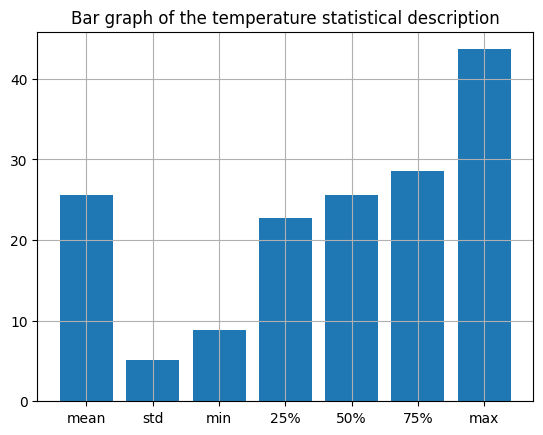

In [34]:
plt.grid(True)
plt.bar(df.temperature.describe().drop('count').index,df.temperature.describe().drop('count').values)
plt.title("Bar graph of the temperature statistical description")
plt.show()

In [35]:
Q1t,Q3t = df.temperature.quantile([0.20,0.80])

In [36]:
IQRt = (Q3t - Q1t)

In [37]:
lower_limitT = (Q1t - 1.5*IQRt)
upper_limitT = (Q3t + 1.5*IQRt)


In [38]:
lower_limitT, upper_limitT

(10.786997731999989, 40.13825667600001)

In [39]:
mask_temp = ((df.temperature > lower_limitT) & (df.temperature < upper_limitT))

### Clean Humidity

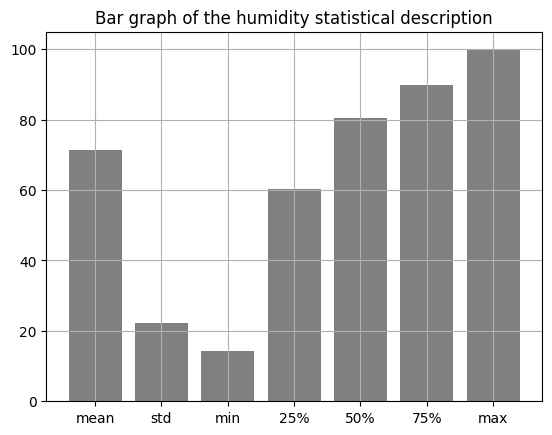

In [40]:
plt.grid(True)
plt.bar(df.humidity.describe().drop('count').index,df.humidity.describe().drop('count').values,color='gray')
plt.title("Bar graph of the humidity statistical description")
plt.show()

In [41]:
Q1hum,Q3hum = df.humidity.quantile([0.24,0.75])
IQRhum = (Q3hum - Q1hum)
lower_limithum = (Q1hum - 1.5*IQRhum)
upper_limithum = (Q3hum + 1.5*IQRhum)

In [42]:
lower_limithum, upper_limithum

(13.398188805500006, 135.87911992469998)

In [43]:
mask_hum = ((df.humidity > lower_limithum) & (df.humidity < upper_limithum))

### Clean PH

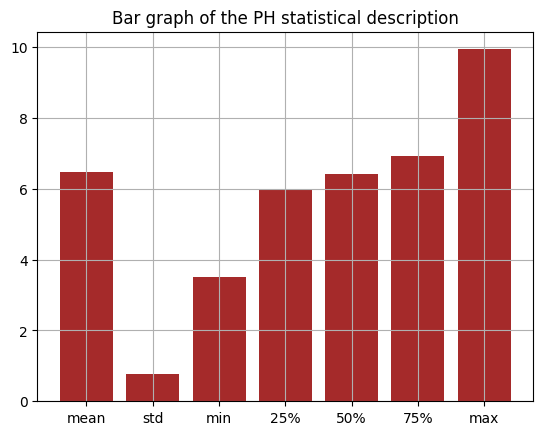

In [44]:
plt.grid(True)
plt.bar(df.ph.describe().drop('count').index,df.ph.describe().drop('count').values,color='brown')
plt.title("Bar graph of the PH statistical description")
plt.show()

In [45]:
Q1ph,Q3ph = df.ph.quantile([0.20,0.80])
IQRph = (Q3ph - Q1ph)
lower_limitph = (Q1ph - 1.5*IQRph)
upper_limitph = (Q3ph + 1.5*IQRph)


In [46]:
lower_limitph, upper_limitph

(4.0816057144, 8.819215437599999)

In [47]:
mask_ph = ((df.ph > lower_limitph) & (df.ph < upper_limitph))

### Clean Rainfall

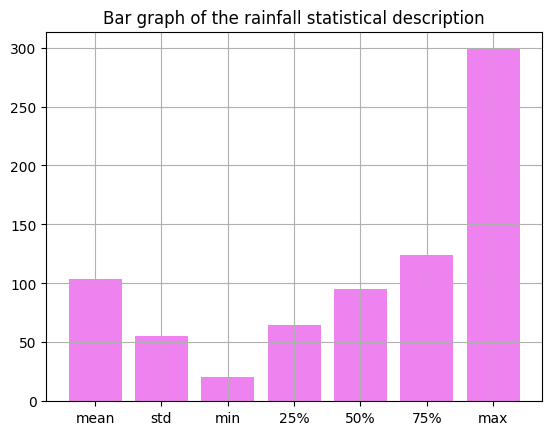

In [48]:
plt.grid(True)
plt.bar(df.rainfall.describe().drop('count').index,df.rainfall.describe().drop('count').values,color='violet')
plt.title("Bar graph of the rainfall statistical description")
plt.show()

In [49]:
Q1rain,Q3rain = df.rainfall.quantile([0.25,0.80])
IQRrain = (Q3rain - Q1rain)
lower_limitrain = (Q1rain - 1.5*IQRrain)
upper_limitrain = (Q3rain + 1.5*IQRrain)


In [50]:
lower_limitrain, upper_limitrain

(-60.35169142000002, 272.7239817)

In [51]:
mask_rain = ((df.rainfall > lower_limitrain) & (df.rainfall < upper_limitrain))

In [52]:
#Getting the cleaned portion of the data and dropping the outliers
def wrangleOutliers(data):
  df = data[mask_p & mask_temp & mask_hum & mask_ph & mask_rain & mask_k]
  return df

In [53]:
df = wrangleOutliers(df)

##### DISPLAYING THE CLEANED BOXPLOT OF EACH COLUMN IN THE DATASET

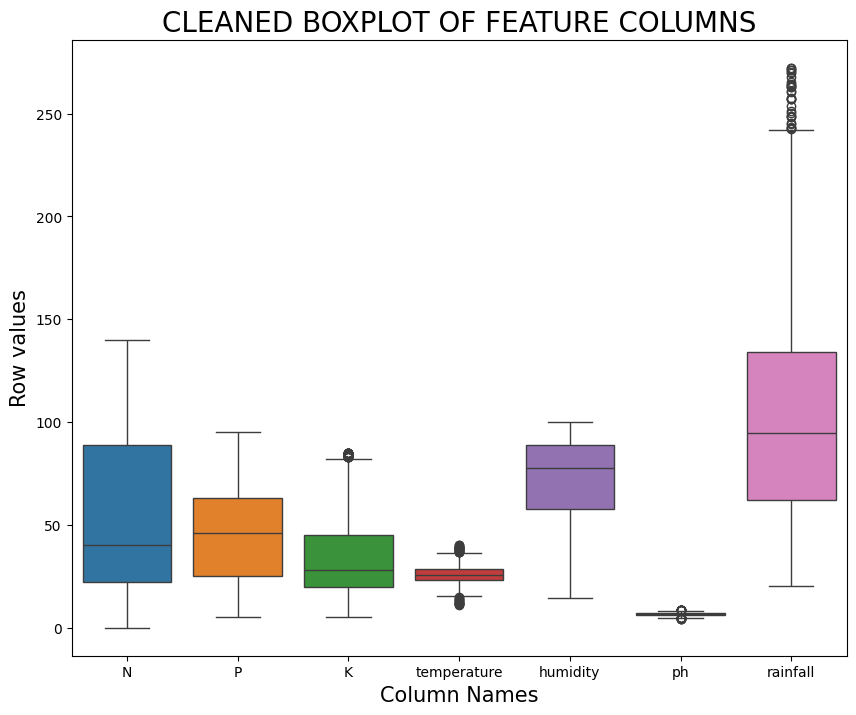

In [54]:
plt.figure(figsize=(10,8))
sns.boxplot(df.drop("label",axis=1))
plt.title("CLEANED BOXPLOT OF FEATURE COLUMNS",fontsize=20)
plt.xlabel("Column Names",fontsize=15)
plt.ylabel("Row values",fontsize=15)
plt.show()

##### VISUALISATION TO IDENTIFY THE TOTAL PERCENTAGE OF EACH CROP IN A PIE CHART FORMAT

In [55]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [56]:
encode.inverse_transform(df.label.unique()) #Our target columns unique values

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'watermelon', 'muskmelon', 'orange', 'papaya',
       'coconut', 'cotton', 'jute', 'coffee'], dtype=object)

In [57]:
df.label.nunique() # Total number of the unique values

20

In [58]:
pie_crops = df.groupby("label")["label"].value_counts() #Getting the sum of each unique value in the Label column

In [59]:
labels= ['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'watermelon', 'muskmelon', 'orange', 'papaya',
       'coconut', 'cotton', 'jute', 'coffee'] # labels for the pie chart


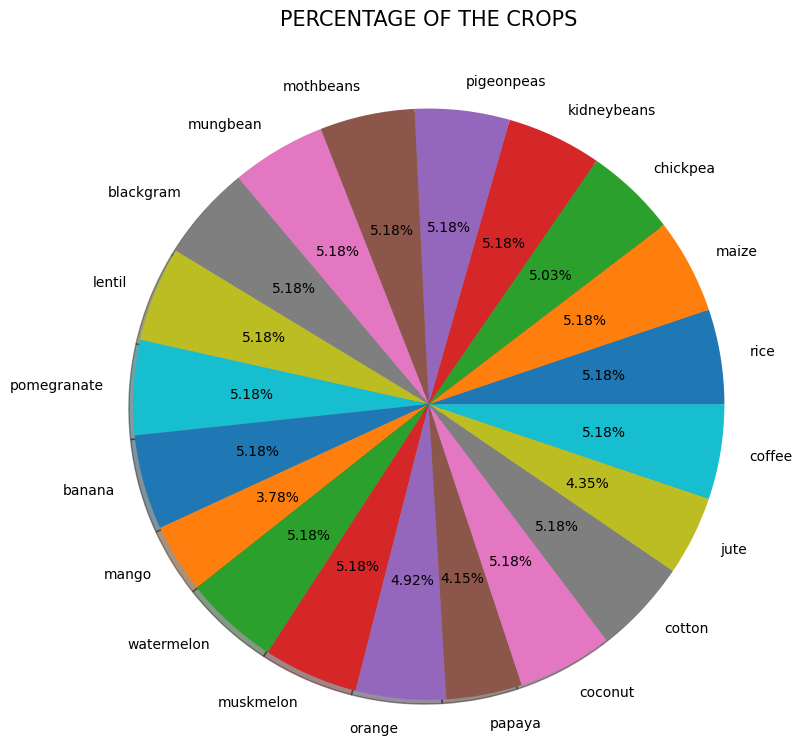

In [60]:
plt.pie(pie_crops,autopct="%.2f%%",radius=2,labels=labels,shadow=True)
plt.title("PERCENTAGE OF THE CROPS"+'\n'*8,fontsize=15)
plt.show()

In [61]:
#Margin of imbalance is less, with lowest quantity of 3.78% and max at 5.18% after dropping outliers

## Building the Machine Learning model

In [62]:
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,20
1,85,58,41,21.770462,80.319644,7.038096,226.655537,20
2,60,55,44,23.004459,82.320763,7.840207,263.964248,20
3,74,35,40,26.491096,80.158363,6.980401,242.864034,20
4,78,42,42,20.130175,81.604873,7.628473,262.717340,20
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,5
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,5
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,5
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,5


In [63]:
#Dividing the dataframe into Feature columns and Targe column

X = df.drop("label",axis=1)
y = encode.inverse_transform(df.label)

###### Dividing the data into training(70%) set, validating(15%) and testing(15%) datasets

In [64]:
X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size=0.3,random_state=30)

In [65]:
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=25)

In [66]:
num_columns = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'] #storing the numerical columns in a num_columns

###### NUMERICAL PIPELINE FOR FILLING NAN VALUES AND SCALING THE NUMERICAL COLUMNS

In [67]:

numerical_pipe = Pipeline(steps=[
    ("impute",SimpleImputer(strategy='mean')),
    ("scale",StandardScaler())


])

numerical_pipe_1 = Pipeline(steps=[
    ("impute",SimpleImputer(strategy='mean')),
    ("scale",MinMaxScaler())


])



###### TRANFORMING THE NUMERICAL COLUMNS USING A COLUMN TRANSFORMER

In [68]:
transformer = ColumnTransformer(transformers=[
    ("num_pipe",numerical_pipe,num_columns)
],
    remainder='drop',
    n_jobs=-1
)

transformer_1 = ColumnTransformer(transformers=[
    ("num_pipe_1",numerical_pipe_1,num_columns)
],
    remainder='drop',
    n_jobs=-1
)

###### USING THE VOTING CLASSIFIER TO COMBINE DIFFERENT ML ALGORITHMS TO GET THE BEST PERFORMING RESULTS

In [69]:
voting = VotingClassifier(estimators=[
    ("XGB",XGBClassifier()),
    ("Rforest",RandomForestClassifier(n_estimators=100,)),
    ("GBoost",GradientBoostingClassifier(n_estimators=100)),
    ("Dtree",DecisionTreeClassifier()),
    ("GNB",GaussianNB()),
    ("AdaBoost",AdaBoostClassifier())



],
    voting='soft'

                        )

In [70]:
len(X.columns)

7

In [71]:
model = Sequential([
    keras.layers.Dense(128, input_shape=(len(X.columns),), activation="relu"),
    keras.layers.Dropout(0.3),  # Prevents overfitting
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(len(set(y)), activation="softmax") # Correct for multi-class classification
])

model.compile(
  optimizer="sgd",
  loss="categorical_crossentropy",
  metrics=["accuracy"]
  )

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [98]:
one = OneHotEncoder()
y_train_ = one.fit_transform(y_train.reshape(-1,1)).toarray()
y_val_ = one.transform(y_val.reshape(-1,1)).toarray()

In [134]:
#Using Neural Networks
#Changing various gradient descent types
def ANN(g_descent):
  model = Sequential([
      keras.layers.Dense(100,input_shape=(7,),activation="relu"),
      keras.layers.Dropout(0.2),
      keras.layers.Dense(80,activation="relu"),
      keras.layers.Dense(50,activation="relu"),
      keras.layers.Dense(len(set(y)),activation="softmax")
  ])

  model.compile(
      optimizer=g_descent,
      loss="categorical_crossentropy",
      metrics=["accuracy"]
  )
  return model

In [135]:
model_0 = ANN("adam") #Adam optimizer
model_1 = ANN('sgd') #Stochastic Gradient Descent
model_2 = ANN("rmsprop") #RMSProp optimizer

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [136]:
hist=model_0.fit(X_train,y_train_,epochs=100,validation_data=(X_val,y_val_))
#

#

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1363 - loss: 7.4577 - val_accuracy: 0.3045 - val_loss: 2.0934
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2911 - loss: 2.5616 - val_accuracy: 0.4844 - val_loss: 1.6269
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3993 - loss: 1.9978 - val_accuracy: 0.6125 - val_loss: 1.3090
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5022 - loss: 1.5435 - val_accuracy: 0.6955 - val_loss: 0.9238
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6022 - loss: 1.1588 - val_accuracy: 0.7439 - val_loss: 0.7949
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6881 - loss: 0.9196 - val_accuracy: 0.7993 - val_loss: 0.5654
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7274 - loss: 0.7814 - val_accuracy: 0.8235 - val_loss: 0.4960
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7704 - loss: 0.6290 - val_accuracy: 0.8720 - v

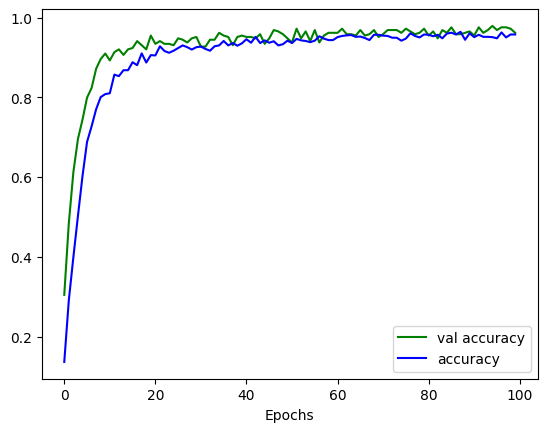

In [138]:
plt.plot(hist.history['val_accuracy'],color='green',label='val accuracy')
plt.plot(hist.history['accuracy'],color='b',label='accuracy')
plt.legend()
plt.xlabel("Epochs");

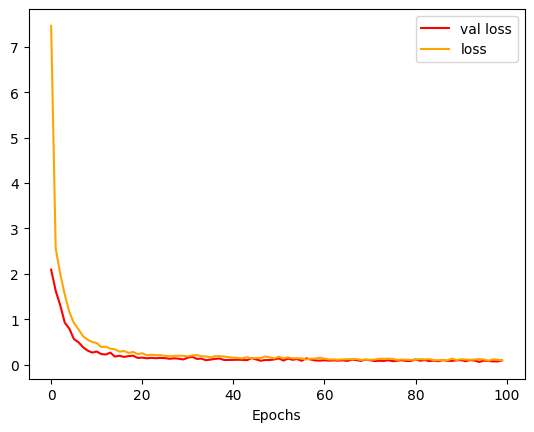

In [139]:
plt.plot(hist.history['val_loss'],color='red',label='val loss')
plt.plot(hist.history['loss'],color='orange',label='loss')
plt.legend()
plt.xlabel("Epochs");

In [128]:
model_1.fit(X_train,y_train_,epochs=100)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0667 - loss: 4.6135
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2511 - loss: 2.4652
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4304 - loss: 1.7936
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5444 - loss: 1.3842
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6044 - loss: 1.1231
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6207 - loss: 1.0304
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6756 - loss: 0.9073
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6822 - loss: 0.8594
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7133 - loss: 0.7704
Epoch 10/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7289 - loss: 0.7095
Epoch 11/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7526 - loss: 0.6688
Epoch 12/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy:

In [129]:
model_3.fit(X_train,y_train_,epochs=100)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1911 - loss: 0.0648
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1978 - loss: 0.0648
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1904 - loss: 0.0643
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1948 - loss: 0.0649
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1963 - loss: 0.0650
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1763 - loss: 0.0666
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1933 - loss: 0.0645
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2000 - loss: 0.0641
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1978 - loss: 0.0642
Epoch 10/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1867 - loss: 0.0648
Epoch 11/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1837 - loss: 0.0660
Epoch 12/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy:

###### CREATING A MAKE PIPELINE TO PASS THE TRANSFORMER AND THE VOTING ALGORITHM

In [111]:
mk_model = make_pipeline(transformer,voting)
mk_model_1 = make_pipeline(transformer_1,voting)

In [112]:
print(f"\t\tTHE PIPELINE FOR DATA PREPROCESSING AND MODEL TRAINING\n"+'_'*80)
mk_model_1.fit(X_train,y_train) #Traing the model using the training data with MinMax scaling

		THE PIPELINE FOR DATA PREPROCESSING AND MODEL TRAINING
________________________________________________________________________________


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(n_jobs=-1,
                                   transformers=[('num_pipe_1',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer()),
                                                                  ('scale',
                                                                   MinMaxScaler())]),
                                                  ['N', 'P', 'K', 'temperature',
                                                   'humidity', 'ph',
                                                   'rainfall'])])),
                ('votingclassifier',
                 VotingClassifier(estimators=[('XGB',
                                               XGBClassifier(base_score=None,
                                                             booster=None,
                                                             callbacks=None,
                                                             colsample_byle...
                                                             max_depth=None,
                                                             max_leaves=None,
                                                             min_child_weight=None,
                                                             missing=nan,
                                                             monotone_constraints=None,
                                                             multi_strategy=None,
                                                             n_estimators=None,
                                                             n_jobs=None,
                                                             num_parallel_tree=None, ...)),
                                              ('Rforest',
                                               RandomForestClassifier()),
                                              ('GBoost',
                                               GradientBoostingClassifier()),
                                              ('Dtree',
                                               DecisionTreeClassifier()),
                                              ('GNB', GaussianNB()),
                                              ('AdaBoost',
                                               AdaBoostClassifier())],
                                  voting='soft'))])

In [113]:
mk_model_1.score(X_val,y_val)

0.9965397923875432

### Evaluating the model perfomance

In [114]:
y_predict = mk_model_1.predict(X_test) #predicted values of the unseen data(testing data)

In [115]:
cm = confusion_matrix(y_test,y_predict) #confusion matrix for model performance evaluation

In [116]:
cr = classification_report(y_test,y_predict) #Providing the report of the model

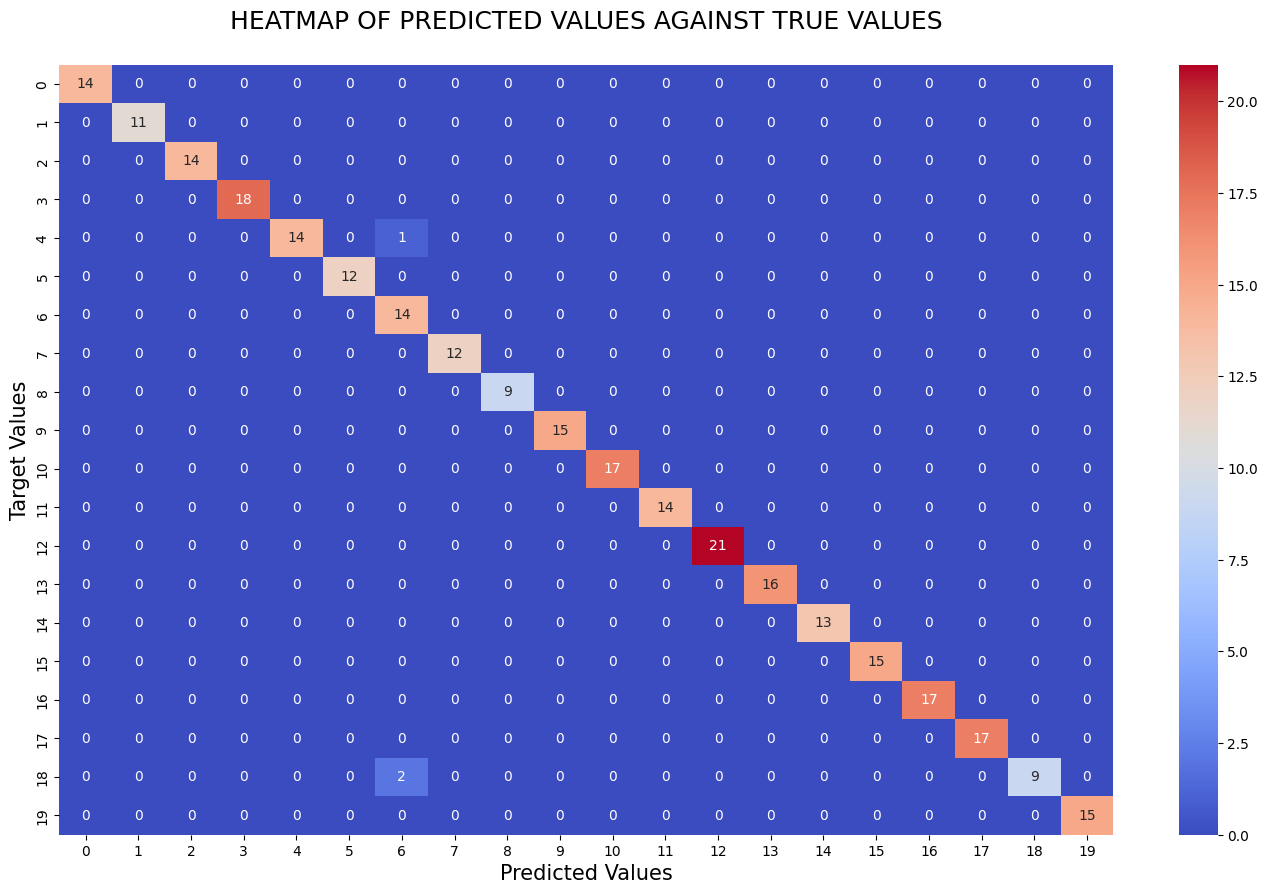

In [117]:
plt.figure(figsize=(17,10))
sns.heatmap(cm,annot=True,cmap='coolwarm')
plt.title("HEATMAP OF PREDICTED VALUES AGAINST TRUE VALUES\n",fontsize=18)
plt.ylabel("Target Values",fontsize=15)
plt.xlabel("Predicted Values",fontsize=15)
plt.show()

##### A SUMMARY REPORT ON THE MODEL PERFORMANCE

In [118]:
print(f"\t\tTHE CLASSIFICATION REPORT\n"+'_'*53)
print(cr)

		THE CLASSIFICATION REPORT
_____________________________________________________
              precision    recall  f1-score   support

      banana       1.00      1.00      1.00        14
   blackgram       1.00      1.00      1.00        11
    chickpea       1.00      1.00      1.00        14
     coconut       1.00      1.00      1.00        18
      coffee       1.00      0.93      0.97        15
      cotton       1.00      1.00      1.00        12
        jute       0.82      1.00      0.90        14
 kidneybeans       1.00      1.00      1.00        12
      lentil       1.00      1.00      1.00         9
       maize       1.00      1.00      1.00        15
       mango       1.00      1.00      1.00        17
   mothbeans       1.00      1.00      1.00        14
    mungbean       1.00      1.00      1.00        21
   muskmelon       1.00      1.00      1.00        16
      orange       1.00      1.00      1.00        13
      papaya       1.00      1.00      1.00        15

### Saving the model using joblib

In [119]:
import joblib as jb

In [120]:
crop_model = jb.dump(mk_model_1,"crop-recommendation.pkl")

In [121]:
crop_model = jb.load("crop-recommendation.pkl")

# Testing the model

In [ ]:
X_test[10:15]

In [ ]:
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [ ]:
X_test[10:15], "________________" ,y_test[10:15]

In [ ]:
crop_model.predict(X_test)[10]

In [ ]:
crop_model.predict(X_test[10:15])

In [ ]:
y_test[10:15]

### WRITE MY REPORT ON THE CROP RECOMENDATION PREDICTION MODEL

##### This project is a machine learning based recomendation system.
##### Which uses the python programming language for various data cleaning, feature engineerng and its analysis
#####
#####